# Fase 1 – Modelo predictivo: precio de vehículos en Australia

**Curso:** Modelos y Simulación de Sistemas I – Proyecto Integrador
**Dataset:** [Australian Vehicle Prices (Kaggle)](https://www.kaggle.com/datasets/nelgiriyewithana/australian-vehicle-prices)
**Tipo de problema:** Regresión supervisada · **Variable objetivo:** `Price` (AUD)

## Contenido
1. Configuración y carga de datos
2. Verificación de requisitos del dataset
3. División train/test (antes de cualquier análisis que aprenda de los datos)
4. Análisis exploratorio (solo con train)
5. Preparación de datos: `Pipeline` de scikit-learn
6. Comparación de modelos con validación cruzada
7. Ajuste de hiperparámetros
8. Evaluación final en test
9. Interpretación del modelo
10. Guardado del modelo y verificación de carga
11. Conclusiones

### Estrategia para evitar fuga de información
- La división train/test se hace **al inicio**; el conjunto de test solo se usa **una vez**, en la sección 8.
- Toda transformación que *aprende* de los datos (imputación, escalado, One-Hot, Target Encoding) está dentro de un `Pipeline`, así que en validación cruzada se ajusta solo con los pliegues de entrenamiento.
- El `TargetEncoder` de scikit-learn usa *cross-fitting* interno, por lo que no codifica una fila con su propio precio.
- La limpieza de `features.py` es **sin estado** (reglas fijas fila a fila, p. ej. extraer `2.2` de `"4 cyl, 2.2 L"`), por lo que no filtra información entre conjuntos.
- La selección de modelo e hiperparámetros se hace solo con validación cruzada sobre train.

## 1. Configuración y carga de datos

In [1]:
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error,
    median_absolute_error, r2_score, root_mean_squared_error,
)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

# Módulo propio con la limpieza sin estado (debe acompañar al modelo guardado)
sys.path.insert(0, str(Path.cwd()))
import features
from features import (
    FEATURES, HIGH_CARD_FEATURES, LOW_CARD_FEATURES, NUMERIC_FEATURES,
    RAW_COLUMNS, TARGET, clean_raw, load_dataset,
)

RANDOM_STATE = 42
DATA_PATH = Path("..") / "data" / "raw" / "australian_vehicle_prices.csv"
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.14.7 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
raw = pd.read_csv(DATA_PATH)
print("Dimensiones:", raw.shape)
raw.head()

Dimensiones: (16734, 19)


,Brand,Year,Model,Car/Suv,Title,UsedOrNew,Transmission,Engine,DriveType,FuelType,FuelConsumption,Kilometres,ColourExtInt,Location,CylindersinEngine,BodyType,Doors,Seats,Price
0,Ssangyong,2022.0,Rexton,Sutherland Isuzu Ute,2022 Ssangyong Rexton Ultimate (awd),DEMO,Automatic,"4 cyl, 2.2 L",AWD,Diesel,8.7 L / 100 km,5595,White / Black,"Caringbah, NSW",4 cyl,SUV,4 Doors,7 Seats,51990
1,MG,2022.0,MG3,Hatchback,2022 MG MG3 Auto Excite (with Navigation),USED,Automatic,"4 cyl, 1.5 L",Front,Premium,6.7 L / 100 km,16,Black / Black,"Brookvale, NSW",4 cyl,Hatchback,5 Doors,5 Seats,19990
2,BMW,2022.0,430I,Coupe,2022 BMW 430I M Sport,USED,Automatic,"4 cyl, 2 L",Rear,Premium,6.6 L / 100 km,8472,Grey / White,"Sylvania, NSW",4 cyl,Coupe,2 Doors,4 Seats,108988
3,Mercedes-Benz,2011.0,E500,Coupe,2011 Mercedes-Benz E500 Elegance,USED,Automatic,"8 cyl, 5.5 L",Rear,Premium,11 L / 100 km,136517,White / Brown,"Mount Druitt, NSW",8 cyl,Coupe,2 Doors,4 Seats,32990
4,Renault,2022.0,Arkana,SUV,2022 Renault Arkana Intens,USED,Automatic,"4 cyl, 1.3 L",Front,Unleaded,6 L / 100 km,1035,Grey / Black,"Castle Hill, NSW",4 cyl,SUV,4 Doors,5 Seats,34990


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 16734 entries, 0 to 16733
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Brand              16733 non-null  str    
 1   Year               16733 non-null  float64
 2   Model              16733 non-null  str    
 3   Car/Suv            16706 non-null  str    
 4   Title              16733 non-null  str    
 5   UsedOrNew          16733 non-null  str    
 6   Transmission       16733 non-null  str    
 7   Engine             16733 non-null  str    
 8   DriveType          16733 non-null  str    
 9   FuelType           16733 non-null  str    
 10  FuelConsumption    16733 non-null  str    
 11  Kilometres         16733 non-null  str    
 12  ColourExtInt       16733 non-null  str    
 13  Location           16284 non-null  str    
 14  CylindersinEngine  16733 non-null  str    
 15  BodyType           16452 non-null  str    
 16  Doors              15130 non-null

## 2. Verificación de requisitos del dataset

La guía exige: variable objetivo clara, clasificación/regresión, ≥ 1.000 observaciones, ≥ 5 predictoras, no ser serie de tiempo y que **alguna predictora tenga entre 0,1 % y 2 % de valores nulos**.

Además de los `NaN` explícitos, el dataset usa `"-"` y `"- / -"` como marcadores de dato faltante, por lo que se reportan ambos.

In [4]:
explicit = raw.isna().mean() * 100
hidden = raw.apply(lambda s: s.astype(str).str.strip().isin(["-", "- / -"])).mean() * 100
nulls = pd.DataFrame({
    "% NaN explícito": explicit.round(3),
    "% '-' (oculto)": hidden.round(3),
    "% total": (explicit + hidden).round(3),
}).sort_values("% total", ascending=False)
nulls

,% NaN explícito,% '-' (oculto),% total
Seats,10.189,0.000,10.189
FuelConsumption,0.006,10.141,10.147
CylindersinEngine,0.006,10.004,10.010
Engine,0.006,10.004,10.010
Doors,9.585,0.000,9.585
FuelType,0.006,3.807,3.813
Kilometres,0.006,3.532,3.538
Location,2.689,0.000,2.689
ColourExtInt,0.006,2.145,2.151
BodyType,1.685,0.000,1.685


In [5]:
predictors = [c for c in raw.columns if c != TARGET]
in_range = explicit[predictors][(explicit[predictors] >= 0.1) & (explicit[predictors] <= 2)]
checks = {
    "Observaciones ≥ 1.000": len(raw) >= 1000,
    "Predictoras ≥ 5": len(predictors) >= 5,
    "Objetivo numérico (regresión)": pd.to_numeric(raw[TARGET], errors="coerce").notna().mean() > 0.99,
    "Alguna predictora con 0,1 %–2 % de nulos": len(in_range) > 0,
}
for k, v in checks.items():
    print(f"{'✔' if v else '✘'} {k}")
print("\nPredictoras en el rango 0,1 %–2 %:", in_range.round(3).to_dict())

✔ Observaciones ≥ 1.000
✔ Predictoras ≥ 5
✔ Objetivo numérico (regresión)
✔ Alguna predictora con 0,1 %–2 % de nulos

Predictoras en el rango 0,1 %–2 %: {'Car/Suv': 0.167, 'BodyType': 1.685}


**Observaciones:**
- `Car/Suv` (≈ 0,17 %) y `BodyType` (≈ 1,69 %) cumplen el requisito de nulos entre 0,1 % y 2 %.
- `Doors`, `Seats`, `Engine`, `FuelConsumption` y `CylindersinEngine` tienen ~10 % de faltantes al contar el marcador `"-"`: se imputan dentro del pipeline.
- Aunque existe la columna `Year`, cada fila es un anuncio independiente (no hay una secuencia temporal a pronosticar), por lo que **no** es un problema de series de tiempo.

### Limpieza del objetivo
`Price` viene como texto: contiene `"POA"` (*Price On Application*, precio a consultar) y algunos nulos. Estas filas **no se imputan** (imputar el objetivo inventaría etiquetas), se eliminan. También se elimina un precio evidentemente erróneo (< 500 AUD, p. ej. un Alfa Romeo 2006 a 88 AUD). Es una regla fija definida a priori, no aprendida de los datos.

In [6]:
price_raw = pd.to_numeric(raw[TARGET], errors="coerce")
print("Filas con Price = 'POA':", (raw[TARGET] == "POA").sum())
print("Filas con Price nulo:   ", raw[TARGET].isna().sum())
print("Filas con Price < 500:  ", (price_raw < features.MIN_VALID_PRICE).sum())

X, y = load_dataset(DATA_PATH)
print(f"\nDataset utilizable: {X.shape[0]} filas ({len(raw) - len(X)} eliminadas) y {X.shape[1]} columnas crudas")

Filas con Price = 'POA': 50
Filas con Price nulo:    3
Filas con Price < 500:   1



Dataset utilizable: 16680 filas (54 eliminadas) y 18 columnas crudas


## 3. División train/test

Se reserva el **20 %** para test. La división se estratifica por deciles del precio para que ambos conjuntos tengan una distribución de precios similar (el precio tiene una cola larga de autos de lujo).

In [7]:
price_bins = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_bins
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(0)

Train: (13344, 18)  |  Test: (3336, 18)


,train,test
count,13344.0,3336.0
mean,37348.0,37134.0
std,37824.0,34476.0
min,900.0,1895.0
25%,18999.0,18995.0
50%,29500.0,29528.0
75%,43990.0,43900.0
max,1500000.0,499990.0


## 4. Análisis exploratorio (solo con train)

Para no tomar decisiones influidas por el conjunto de test, la exploración se hace sobre `X_train`/`y_train`. Primero se aplica la limpieza sin estado de `features.clean_raw` para trabajar con variables numéricas.

### 4.1 Construcción de variables (`features.clean_raw`)

| Variable del modelo | Origen | Transformación |
|---|---|---|
| `Year` | `Year` | numérica |
| `Kilometres` | `Kilometres` | texto → número (`"- / -"` → NaN) |
| `EngineLitres` | `Engine` | `"4 cyl, 2.2 L"` → 2.2 |
| `Cylinders` | `CylindersinEngine` | `"4 cyl"` → 4; `"0 L"` (eléctrico) → 0 |
| `FuelConsumption` | `FuelConsumption` | `"8.7 L / 100 km"` → 8.7 |
| `Doors`, `Seats` | `Doors`, `Seats` | `" 4 Doors"` → 4 (valores mal ubicados como `"5 Seats"` en `Doors` → NaN) |
| `State` | `Location` | `"Caringbah, NSW"` → `NSW` |
| `ColourExt` | `ColourExtInt` | `"White / Black"` → `White` |
| `UsedOrNew`, `Transmission`, `DriveType`, `FuelType`, `BodyType`, `Brand`, `Model` | iguales | `"-"` → NaN |

**Columnas descartadas:**
- `Title`: repite año, marca y modelo, y tiene ~8.800 valores únicos (casi un identificador).
- `Car/Suv`: mezcla el tipo de carrocería con textos del anunciante (p. ej. `"Sutherland Isuzu Ute"`); `BodyType` contiene la misma información de forma limpia.
- Ciudad de `Location`: más de 600 valores; se conserva solo el estado.
- Color interior: más de la mitad de los registros no lo tiene.

In [8]:
train_eda = clean_raw(X_train).assign(Price=y_train.values)
train_eda.head()

,Year,Kilometres,EngineLitres,Cylinders,FuelConsumption,Doors,Seats,UsedOrNew,Transmission,DriveType,FuelType,BodyType,State,ColourExt,Brand,Model,Price
10489,2015.0,194392.0,2.0,4.0,8.2,2.0,2.0,USED,Automatic,Front,Diesel,Commercial,QLD,White,Volkswagen,Transporter,25999.0
15631,2008.0,129950.0,NaN,NaN,NaN,NaN,NaN,USED,Automatic,Other,Unleaded,Commercial,NSW,Silver,Mitsubishi,Delica,19900.0
1198,2003.0,58169.0,NaN,NaN,NaN,NaN,NaN,USED,Automatic,Rear,Unleaded,Commercial,NSW,White,Nissan,Elgrand,13900.0
12277,2019.0,59461.0,2.0,4.0,7.4,5.0,5.0,USED,Automatic,Front,Unleaded,Hatchback,SA,Black,Kia,Cerato,23291.0
3913,2016.0,124038.0,NaN,NaN,NaN,NaN,NaN,USED,Automatic,Other,Unleaded,Wagon,NSW,White,Toyota,Corolla,21999.0


In [9]:
train_eda.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Year,13344.0,2016.22,5.24,1940.0,2013.00,2017.0,2020.00,2023.0
Kilometres,12898.0,100289.31,78069.18,1.0,41117.25,85951.5,146714.75,533849.0
EngineLitres,12029.0,2.40,0.92,0.0,2.00,2.2,2.80,9.8
Cylinders,12029.0,4.43,1.12,0.0,4.00,4.0,4.00,12.0
FuelConsumption,12013.0,7.67,2.32,0.0,6.50,7.6,8.80,27.0
Doors,12030.0,4.01,0.70,2.0,4.00,4.0,4.00,5.0
Seats,12009.0,5.10,1.12,2.0,5.00,5.0,5.00,22.0
Price,13344.0,37348.39,37824.22,900.0,18999.00,29500.0,43990.00,1500000.0


### 4.2 Distribución de la variable objetivo

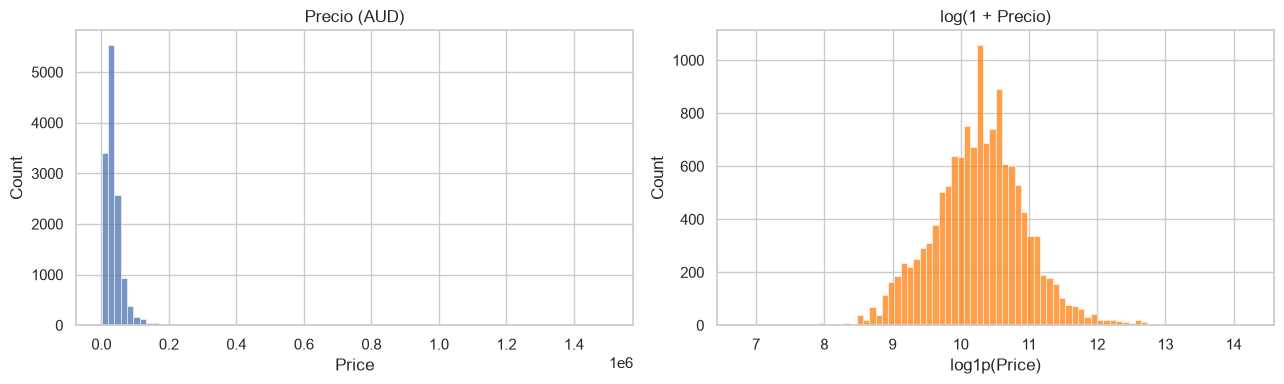

Asimetría precio: 9.32 | Asimetría log-precio: 0.16


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_train, bins=80, ax=axes[0])
axes[0].set(title="Precio (AUD)", xlabel="Price")
sns.histplot(np.log1p(y_train), bins=80, ax=axes[1], color="tab:orange")
axes[1].set(title="log(1 + Precio)", xlabel="log1p(Price)")
plt.tight_layout(); plt.show()
print(f"Asimetría precio: {y_train.skew():.2f} | Asimetría log-precio: {np.log1p(y_train).skew():.2f}")

El precio tiene una fuerte asimetría a la derecha (autos de lujo de hasta 1,5 M AUD). En escala logarítmica la distribución es casi simétrica. Por eso **el modelo se entrena sobre `log1p(Price)`** (con `TransformedTargetRegressor`) y las predicciones se devuelven en AUD. Así los errores se vuelven relativos (un error de 5.000 AUD pesa más en un auto de 15.000 que en uno de 300.000) y los valores extremos pesan menos.

Los autos de lujo **no se eliminan**: son precios reales y el modelo debe poder estimarlos.

### 4.3 Relación de las variables numéricas con el precio

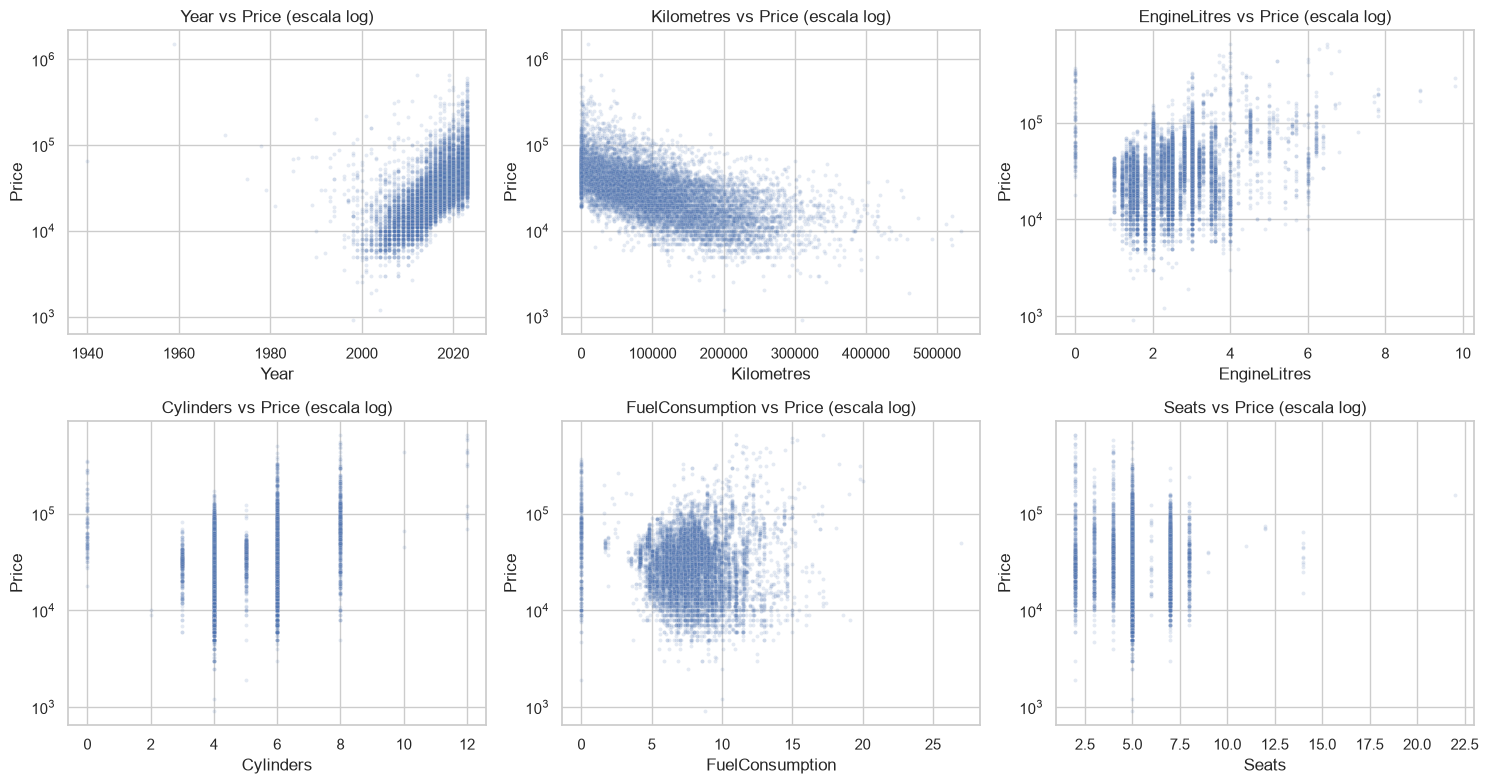

In [11]:
num_cols = ["Year", "Kilometres", "EngineLitres", "Cylinders", "FuelConsumption", "Seats"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.scatterplot(data=train_eda, x=col, y="Price", alpha=0.15, s=8, ax=ax)
    ax.set_yscale("log"); ax.set_title(f"{col} vs Price (escala log)")
plt.tight_layout(); plt.show()

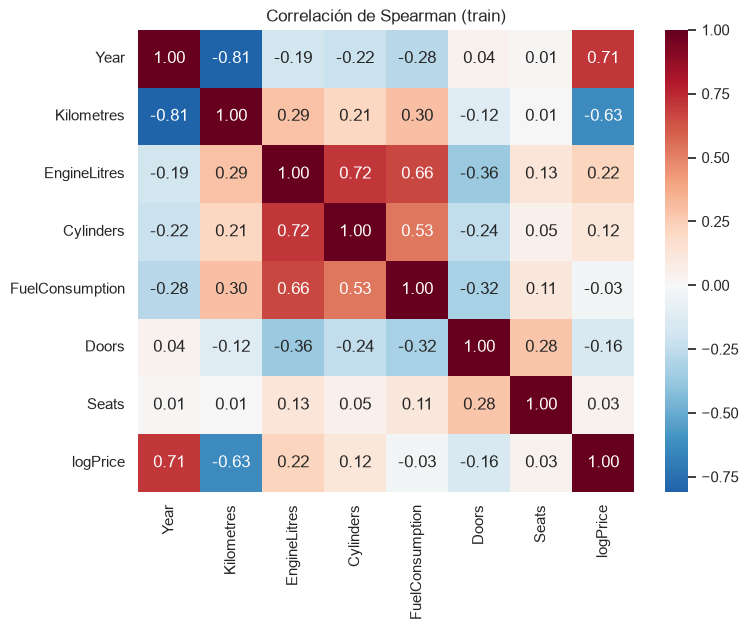

In [12]:
corr = train_eda[NUMERIC_FEATURES].assign(logPrice=np.log1p(train_eda["Price"])).corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación de Spearman (train)"); plt.show()

- **Year** (+) y **Kilometres** (−) son las variables numéricas más relacionadas con el precio: la depreciación domina.
- `EngineLitres` y `Cylinders` están muy correlacionadas entre sí; los modelos de árboles lo manejan bien y Ridge lo controla con regularización.

### 4.4 Variables categóricas

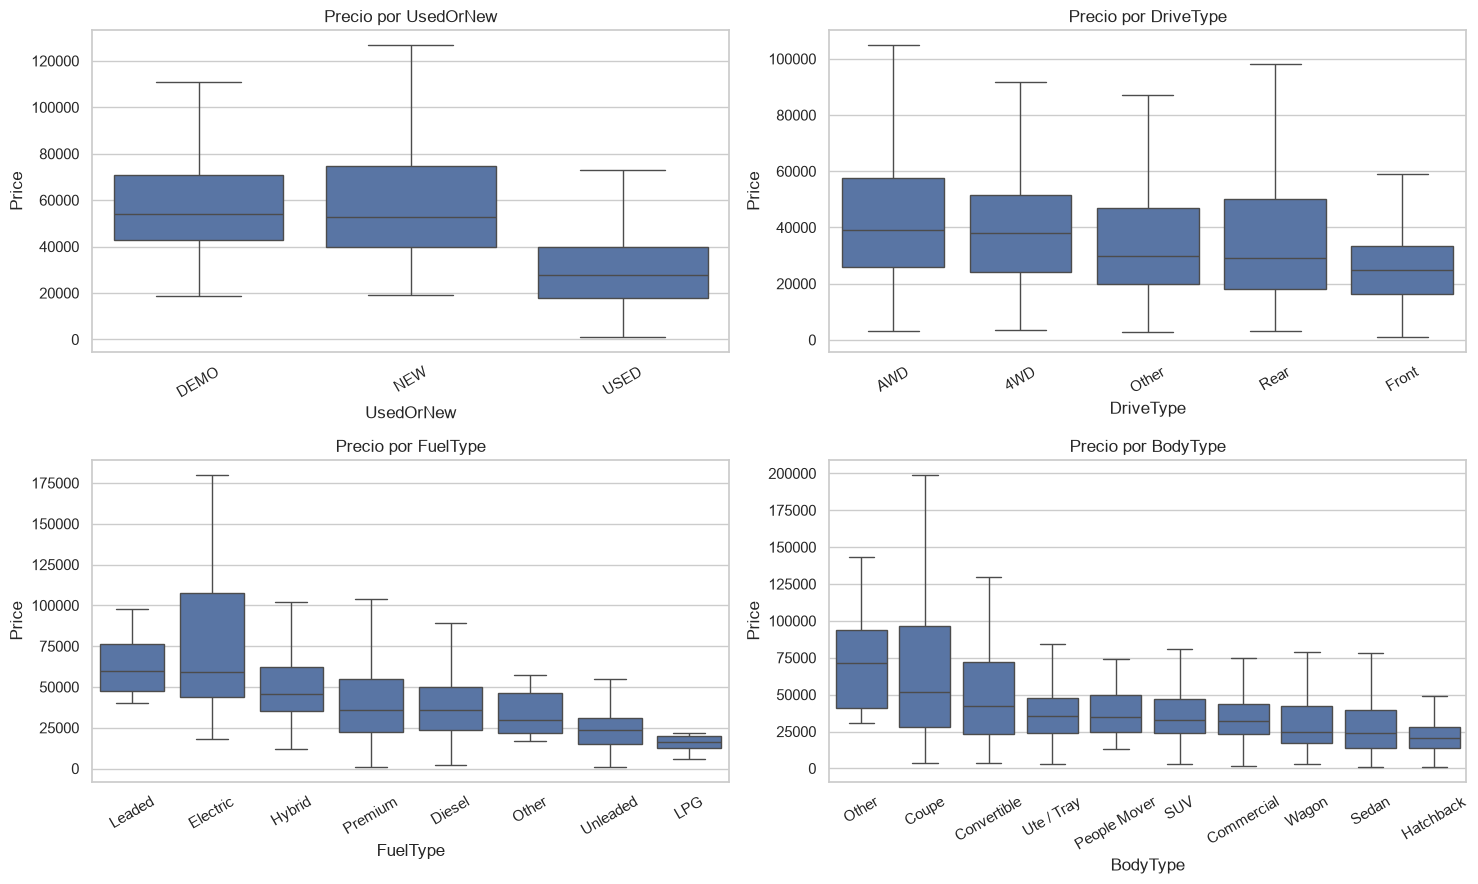

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), ["UsedOrNew", "DriveType", "FuelType", "BodyType"]):
    order = train_eda.groupby(col)["Price"].median().sort_values(ascending=False).index
    sns.boxplot(data=train_eda, x=col, y="Price", order=order, ax=ax, showfliers=False)
    ax.set_title(f"Precio por {col}"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

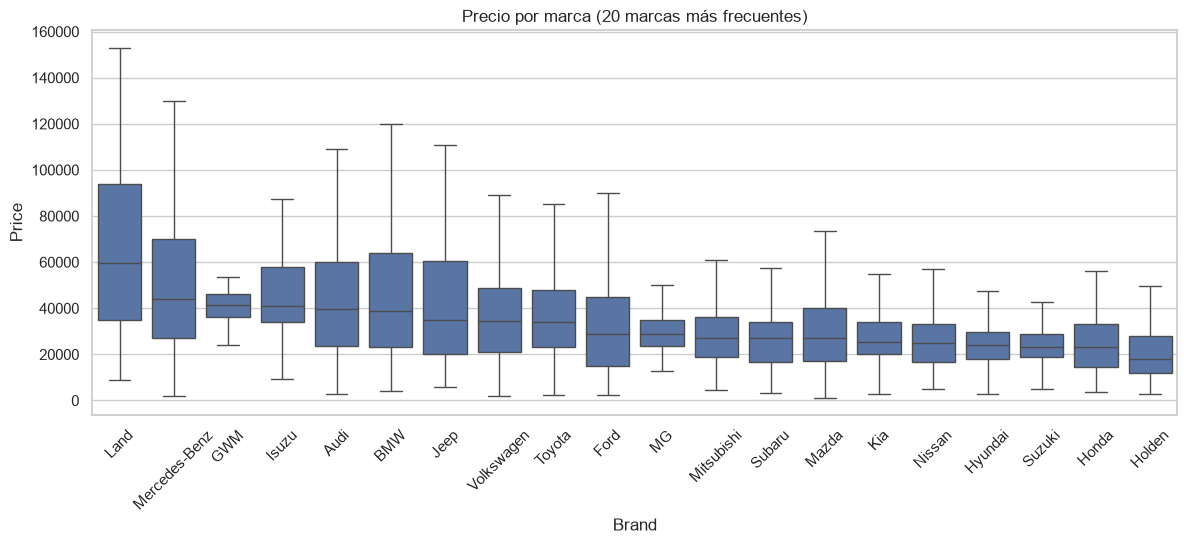

Cardinalidad: {'Brand': 74, 'Model': 735, 'UsedOrNew': 3, 'Transmission': 2, 'DriveType': 5, 'FuelType': 8, 'BodyType': 10, 'State': 8, 'ColourExt': 16}


In [14]:
top_brands = train_eda["Brand"].value_counts().head(20).index
order = (train_eda[train_eda["Brand"].isin(top_brands)]
         .groupby("Brand")["Price"].median().sort_values(ascending=False).index)
plt.figure(figsize=(14, 5))
sns.boxplot(data=train_eda[train_eda["Brand"].isin(top_brands)], x="Brand", y="Price",
            order=order, showfliers=False)
plt.xticks(rotation=45); plt.title("Precio por marca (20 marcas más frecuentes)"); plt.show()

print("Cardinalidad:", {c: train_eda[c].nunique() for c in HIGH_CARD_FEATURES + LOW_CARD_FEATURES})

- La **marca** y el **modelo** separan mucho el precio (p. ej. Porsche/Land Rover vs. Suzuki/Kia).
- `Brand` (~75 valores) y `Model` (~750 valores) tienen **alta cardinalidad**: One-Hot generaría cientos de columnas dispersas y muchos modelos con pocas observaciones. Se usa **Target Encoding** (media suavizada del log-precio por categoría, calculada con *cross-fitting* para no filtrar el objetivo).
- El resto de categóricas tienen pocas categorías → **One-Hot**, agrupando las poco frecuentes (< 20 registros) en una categoría "infrecuente".

## 5. Preparación de datos: `Pipeline`

```
Datos crudos (18 columnas del CSV)
  └─ FunctionTransformer(clean_raw)            → 16 variables limpias (sin estado)
      └─ ColumnTransformer
          ├─ numéricas:  SimpleImputer(mediana, + indicador de faltante) → StandardScaler
          ├─ baja card.: SimpleImputer("Desconocido") → OneHotEncoder(min_frequency=20)
          └─ alta card.: SimpleImputer("Desconocido") → TargetEncoder
      └─ Modelo
Todo envuelto en TransformedTargetRegressor(log1p / expm1)
```

Como la limpieza está dentro del pipeline, **el modelo guardado recibe registros crudos** tal como vienen en el CSV. Esto facilita las fases 2 (`predict.py`) y 3 (API REST).

In [15]:
def build_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    low_card = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                 sparse_output=False)),
    ])
    high_card = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
        ("target_enc", TargetEncoder(target_type="continuous",
                                     cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("low_card", low_card, LOW_CARD_FEATURES),
        ("high_card", high_card, HIGH_CARD_FEATURES),
    ])


def make_model(estimator) -> TransformedTargetRegressor:
    pipe = Pipeline([
        ("clean", FunctionTransformer(clean_raw)),
        ("preprocess", build_preprocessor()),
        ("model", estimator),
    ])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


# Vista rápida de la matriz que recibe el modelo
prep_demo = Pipeline([("clean", FunctionTransformer(clean_raw)), ("preprocess", build_preprocessor())])
prep_demo.set_output(transform="pandas")
Xt_demo = prep_demo.fit_transform(X_train, np.log1p(y_train))
print("Matriz de entrada al modelo:", Xt_demo.shape, "| nulos restantes:", int(Xt_demo.isna().sum().sum()))
Xt_demo.head()

Matriz de entrada al modelo: (13344, 67) | nulos restantes: 0


,num__Year,num__Kilometres,num__EngineLitres,num__Cylinders,num__FuelConsumption,num__Doors,num__Seats,num__missingindicator_Kilometres,num__missingindicator_EngineLitres,num__missingindicator_Cylinders,num__missingindicator_FuelConsumption,num__missingindicator_Doors,num__missingindicator_Seats,low_card__UsedOrNew_DEMO,low_card__UsedOrNew_NEW,...,low_card__ColourExt_Black,low_card__ColourExt_Blue,low_card__ColourExt_Brown,low_card__ColourExt_Desconocido,low_card__ColourExt_Gold,low_card__ColourExt_Green,low_card__ColourExt_Grey,low_card__ColourExt_Orange,low_card__ColourExt_Red,low_card__ColourExt_Silver,low_card__ColourExt_White,low_card__ColourExt_Yellow,low_card__ColourExt_infrequent_sklearn,high_card__Brand,high_card__Model
10489,-0.232325,1.231636,-0.438727,-0.359201,0.243276,-3.034080,-2.918890,-0.185954,-0.330634,-0.330634,-0.332861,-0.330495,-0.333417,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,10.392519,10.329680
15631,-1.569415,0.392479,-0.209674,-0.359201,-0.029150,-0.006919,-0.087628,-0.185954,3.024488,3.024488,3.004254,3.025765,2.999251,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,10.158940,10.008075
1198,-2.524480,-0.542246,-0.209674,-0.359201,-0.029150,-0.006919,-0.087628,-0.185954,3.024488,3.024488,3.004254,3.025765,2.999251,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,10.070746,9.890052
12277,0.531727,-0.525422,-0.438727,-0.359201,-0.119959,1.506661,-0.087628,-0.185954,-0.330634,-0.330634,-0.332861,-0.330495,-0.333417,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.151365,10.045237
3913,-0.041312,0.315493,-0.209674,-0.359201,-0.029150,-0.006919,-0.087628,-0.185954,3.024488,3.024488,3.004254,3.025765,2.999251,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,10.390278,10.064473


## 6. Comparación de modelos (validación cruzada 5-fold sobre train)

| Modelo | Motivo |
|---|---|
| `DummyRegressor` (mediana) | **Línea base**: cualquier modelo útil debe superarla ampliamente |
| `Ridge` | Modelo lineal regularizado, interpretable |
| `RandomForestRegressor` | Ensamble de árboles, captura no linealidades e interacciones |
| `HistGradientBoostingRegressor` | *Boosting* eficiente, suele ser el mejor en datos tabulares |

Métricas (en AUD, sobre la escala original): **MAE**, **RMSE**, **R²** y **MAPE**.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error",
}
candidates = {
    "Dummy (mediana)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                          random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, est in candidates.items():
    res = cross_validate(make_model(est), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({
        "Modelo": name,
        "MAE": -res["test_MAE"].mean(), "MAE (std)": res["test_MAE"].std(),
        "RMSE": -res["test_RMSE"].mean(),
        "R2": res["test_R2"].mean(),
        "MAPE %": -res["test_MAPE"].mean() * 100,
        "Tiempo ajuste (s)": res["fit_time"].mean(),
    })
cv_results = pd.DataFrame(rows).set_index("Modelo").sort_values("MAE")
cv_results.style.format({"MAE": "{:,.0f}", "MAE (std)": "{:,.0f}", "RMSE": "{:,.0f}",
                         "R2": "{:.3f}", "MAPE %": "{:.1f}", "Tiempo ajuste (s)": "{:.1f}"})

,MAE,MAE (std),RMSE,R2,MAPE %,Tiempo ajuste (s)
Modelo,,,,,,
RandomForest,"5,765",433,"18,602",0.753,14.3,4.0
HistGradientBoosting,"5,940",364,"17,502",0.780,14.8,1.0
Ridge,"8,274",363,"23,305",0.619,20.2,0.3
Dummy (mediana),"18,611",452,"38,326",-0.045,61.9,0.3


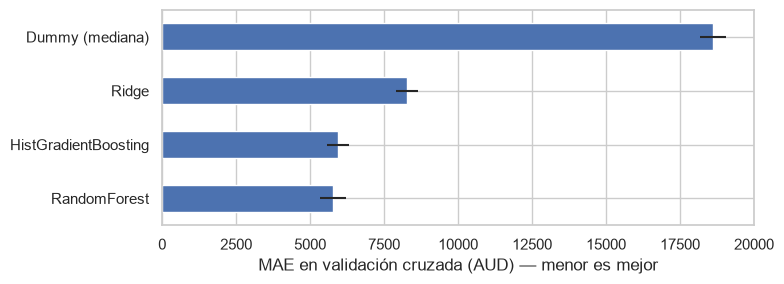

In [17]:
ax = cv_results["MAE"].sort_values().plot.barh(figsize=(8, 3), xerr=cv_results["MAE (std)"])
ax.set(xlabel="MAE en validación cruzada (AUD) — menor es mejor", ylabel="")
plt.tight_layout(); plt.show()

**Análisis de la comparación (5-fold CV en train):**

| Modelo | MAE | RMSE | R² | MAPE |
|---|---|---|---|---|
| Dummy (mediana) | 18.611 | 38.326 | −0,05 | 61,9 % |
| Ridge | 8.274 | 23.305 | 0,62 | 20,2 % |
| RandomForest | 5.765 | 18.602 | 0,75 | 14,3 % |
| HistGradientBoosting | 5.940 | 17.502 | 0,78 | 14,8 % |

- Todos los modelos superan ampliamente la línea base. Los de árboles superan a Ridge, lo que indica relaciones no lineales (p. ej. la depreciación no es lineal con la edad) e interacciones (marca × año).
- Con hiperparámetros por defecto, RandomForest y HistGradientBoosting quedan prácticamente empatados en MAE (la diferencia, ~175 AUD, es menor que la desviación estándar entre pliegues, ~400 AUD). **Se elige HistGradientBoosting para el ajuste** porque tiene mejor RMSE y R² (se equivoca menos en los autos caros), entrena ~3 veces más rápido y produce un archivo de modelo mucho más liviano, lo que importa para contenerizarlo y servirlo por API en las fases 2 y 3.

## 7. Ajuste de hiperparámetros

Se ajusta el `HistGradientBoostingRegressor` con `RandomizedSearchCV` (validación cruzada 5-fold, **solo train**), optimizando el MAE.

In [18]:
param_distributions = {
    "regressor__model__learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "regressor__model__max_iter": [300, 500, 800, 1200],
    "regressor__model__max_leaf_nodes": [15, 31, 63, 127],
    "regressor__model__min_samples_leaf": [5, 10, 20, 40],
    "regressor__model__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    "regressor__model__max_features": [0.5, 0.8, 1.0],
}
search = RandomizedSearchCV(
    make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions=param_distributions,
    n_iter=25, cv=cv, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
)
search.fit(X_train, y_train)

best_params = {k.replace("regressor__model__", ""): v for k, v in search.best_params_.items()}
print("Mejores hiperparámetros:", best_params)
print(f"MAE CV — por defecto: {cv_results.loc['HistGradientBoosting', 'MAE']:,.0f} AUD | "
      f"ajustado: {-search.best_score_:,.0f} AUD")

Mejores hiperparámetros: {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 1200, 'max_features': 0.5, 'learning_rate': 0.05, 'l2_regularization': 1.0}
MAE CV — por defecto: 5,940 AUD | ajustado: 5,370 AUD


In [19]:
top = (pd.DataFrame(search.cv_results_)
       .sort_values("rank_test_score")
       .loc[:, ["rank_test_score", "mean_test_score", "std_test_score", "params"]]
       .head(5))
top["mean_test_score"] = -top["mean_test_score"]
top.rename(columns={"mean_test_score": "MAE CV"})

,rank_test_score,MAE CV,std_test_score,params
9,1,5370.302606,309.524682,"{'regressor__model__min_samples_leaf': 10, 're..."
6,2,5453.025148,382.749305,"{'regressor__model__min_samples_leaf': 5, 'reg..."
21,3,5461.238386,320.419714,"{'regressor__model__min_samples_leaf': 5, 'reg..."
4,4,5492.422675,312.432354,"{'regressor__model__min_samples_leaf': 20, 're..."
7,5,5492.465948,366.415522,"{'regressor__model__min_samples_leaf': 5, 'reg..."


## 8. Evaluación final en test

El modelo ajustado (reentrenado por `RandomizedSearchCV` con **todo** el conjunto de train) se evalúa **una única vez** en test. Este es el estimado honesto del desempeño con datos nuevos.

In [20]:
final_model = search.best_estimator_
y_pred = final_model.predict(X_test)

def regression_metrics(y_true, y_hat) -> dict:
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "MedAE": median_absolute_error(y_true, y_hat),
        "RMSE": root_mean_squared_error(y_true, y_hat),
        "R2": r2_score(y_true, y_hat),
        "R2_log": r2_score(np.log1p(y_true), np.log1p(y_hat)),
        "MAPE": mean_absolute_percentage_error(y_true, y_hat),
    }

test_metrics = regression_metrics(y_test, y_pred)
baseline_pred = np.full(len(y_test), np.median(y_train))
baseline_metrics = regression_metrics(y_test, baseline_pred)

pd.DataFrame({"Modelo final": test_metrics, "Línea base (mediana)": baseline_metrics}).T.style.format(
    {"MAE": "{:,.0f}", "MedAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.3f}", "R2_log": "{:.3f}", "MAPE": "{:.1%}"})

,MAE,MedAE,RMSE,R2,R2_log,MAPE
Modelo final,"4,930","2,573","11,333",0.892,0.924,13.2%
Línea base (mediana),"18,478","11,685","35,306",-0.049,-0.000,62.6%


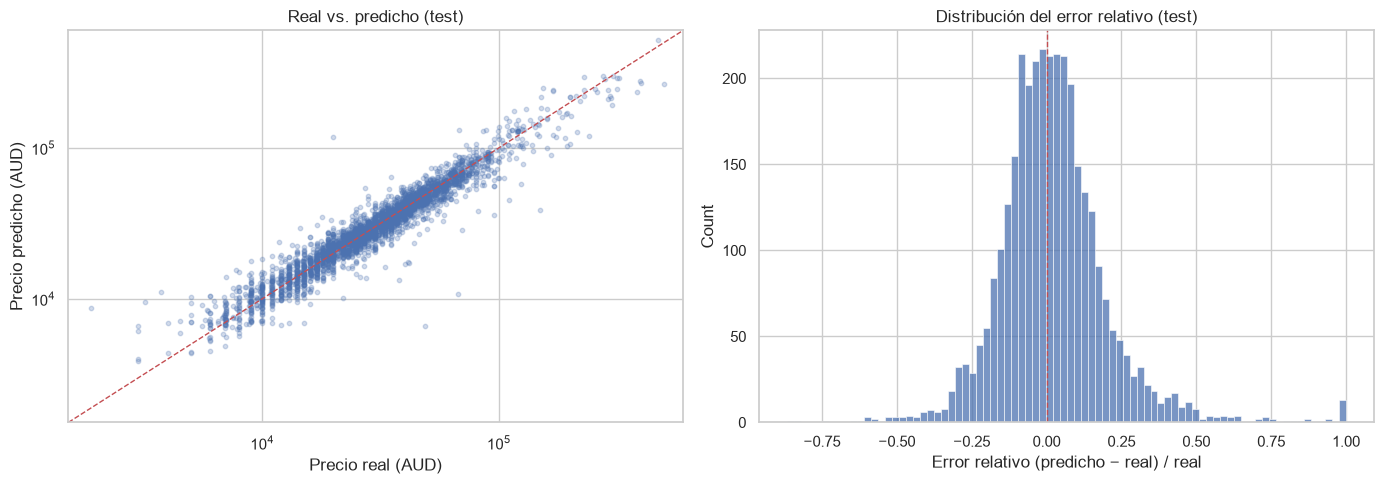

Predicciones con error ≤ 10 %: 53.3%
Predicciones con error ≤ 20 %: 81.5%


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lims = [y_test.min() * 0.8, y_test.max() * 1.2]
axes[0].scatter(y_test, y_pred, alpha=0.25, s=10)
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims,
            xlabel="Precio real (AUD)", ylabel="Precio predicho (AUD)", title="Real vs. predicho (test)")
rel_err = (y_pred - y_test) / y_test
sns.histplot(rel_err.clip(-1, 1), bins=80, ax=axes[1])
axes[1].axvline(0, color="r", ls="--", lw=1)
axes[1].set(xlabel="Error relativo (predicho − real) / real", title="Distribución del error relativo (test)")
plt.tight_layout(); plt.show()
print(f"Predicciones con error ≤ 10 %: {(rel_err.abs() <= 0.10).mean():.1%}")
print(f"Predicciones con error ≤ 20 %: {(rel_err.abs() <= 0.20).mean():.1%}")

### Error por segmento de precio

In [22]:
segments = pd.cut(y_test, bins=[0, 15_000, 30_000, 50_000, 100_000, np.inf],
                  labels=["< 15k", "15k–30k", "30k–50k", "50k–100k", "> 100k"])
seg = (pd.DataFrame({"segment": segments, "y": y_test, "pred": y_pred})
       .groupby("segment", observed=True)
       .apply(lambda g: pd.Series({
           "n": len(g),
           "MAE": mean_absolute_error(g["y"], g["pred"]),
           "MAPE %": mean_absolute_percentage_error(g["y"], g["pred"]) * 100,
       }), include_groups=False))
seg.style.format({"n": "{:.0f}", "MAE": "{:,.0f}", "MAPE %": "{:.1f}"})

,n,MAE,MAPE %
segment,,,
< 15k,565,"1,962",20.1
15k–30k,1211,"2,691",11.9
30k–50k,958,"4,120",10.5
50k–100k,495,"8,488",12.3
> 100k,107,"36,721",20.3


## 9. Interpretación del modelo

Se calcula la **importancia por permutación** sobre test: cuánto empeora el MAE al desordenar aleatoriamente cada columna **cruda**. Como el pipeline recibe datos crudos, la importancia se expresa en términos de las columnas originales del dataset.

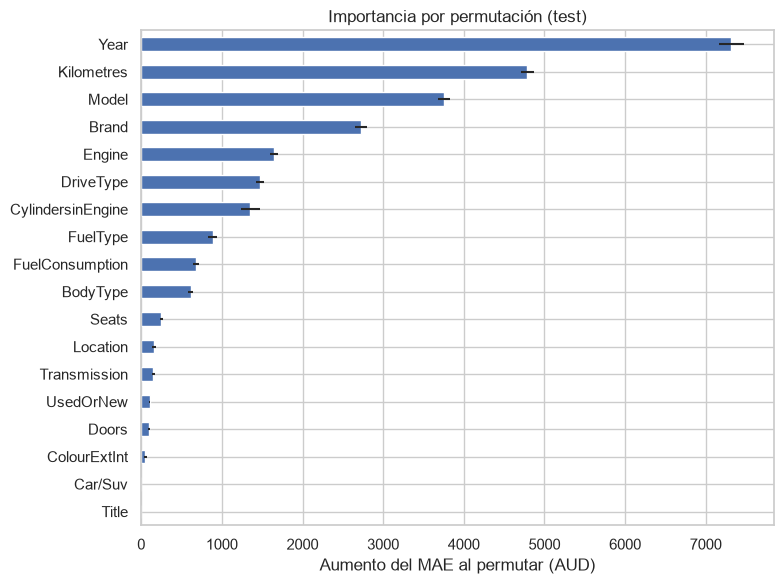

,Aumento del MAE (AUD),std
Year,7319.0,154.0
Kilometres,4788.0,80.0
Model,3756.0,77.0
Brand,2729.0,73.0
Engine,1646.0,49.0
DriveType,1471.0,51.0
CylindersinEngine,1352.0,119.0
FuelType,887.0,55.0
FuelConsumption,679.0,41.0
BodyType,611.0,27.0


In [23]:
perm = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importances = (pd.DataFrame({"Aumento del MAE (AUD)": perm.importances_mean,
                             "std": perm.importances_std}, index=X_test.columns)
               .sort_values("Aumento del MAE (AUD)", ascending=False))
ax = importances["Aumento del MAE (AUD)"].iloc[::-1].plot.barh(
    figsize=(8, 6), xerr=importances["std"].iloc[::-1])
ax.set(title="Importancia por permutación (test)", xlabel="Aumento del MAE al permutar (AUD)")
plt.tight_layout(); plt.show()
importances.round(0)

Las columnas que el pipeline descarta (`Title`, `Car/Suv`) tienen importancia 0, como era de esperar. La antigüedad (`Year`), el kilometraje y la identidad del vehículo (`Model`, `Brand`) explican la mayor parte del precio, lo que es coherente con el EDA.

## 10. Guardado del modelo

Se guardan:
- `models/model_v1.joblib`: el pipeline completo (limpieza + preprocesamiento + modelo + transformación del objetivo).
- `models/model_v1_metadata.json`: versión, fecha, hiperparámetros, métricas de CV y test, variables y versiones de librerías (trazabilidad para las fases 2 y 4).
- `models/sample_input.json`: registros crudos de ejemplo para probar `predict.py` y la API.

> ⚠️ El modelo referencia `features.clean_raw`, así que `features.py` debe estar disponible (mismo directorio o `PYTHONPATH`) para cargarlo.

In [24]:
MODEL_VERSION = "v1"
model_path = MODELS_DIR / f"model_{MODEL_VERSION}.joblib"
joblib.dump(final_model, model_path, compress=3)

metadata = {
    "model_version": MODEL_VERSION,
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "problem": "regression",
    "target": TARGET,
    "target_transform": "log1p / expm1",
    "algorithm": "HistGradientBoostingRegressor",
    "hyperparameters": best_params,
    "input_columns": RAW_COLUMNS,
    "engineered_features": FEATURES,
    "data": {
        "source": "Kaggle - Australian Vehicle Prices",
        "rows_raw": int(len(raw)),
        "rows_used": int(len(X)),
        "rows_train": int(len(X_train)),
        "rows_test": int(len(X_test)),
        "test_size": 0.2,
        "random_state": RANDOM_STATE,
    },
    "cv_mae": float(-search.best_score_),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "baseline_test_metrics": {k: float(v) for k, v in baseline_metrics.items()},
    "library_versions": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}
(MODELS_DIR / f"model_{MODEL_VERSION}_metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

sample = X_test.head(3).astype(object).where(X_test.head(3).notna(), None)
sample_records = [{"input": rec, "actual_price": float(p)}
                  for rec, p in zip(sample.to_dict(orient="records"), y_test.head(3))]
(MODELS_DIR / "sample_input.json").write_text(
    json.dumps(sample_records, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Modelo guardado en {model_path} ({model_path.stat().st_size / 1024:.0f} KB)")

Modelo guardado en models\model_v1.joblib (961 KB)


### Verificación: cargar el modelo y predecir con datos crudos

In [25]:
loaded = joblib.load(model_path)
assert np.allclose(loaded.predict(X_test), y_pred), "El modelo cargado no reproduce las predicciones"

# Un registro nuevo, crudo e incompleto (como llegaría a la API en la fase 3)
new_car = pd.DataFrame([{
    "Brand": "Toyota", "Year": 2019, "Model": "Corolla", "UsedOrNew": "USED",
    "Transmission": "Automatic", "Engine": "4 cyl, 1.8 L", "DriveType": "Front",
    "FuelType": "Hybrid", "FuelConsumption": "4.2 L / 100 km", "Kilometres": "65000",
    "Location": "Parramatta, NSW", "BodyType": "Hatchback", "Doors": " 5 Doors", "Seats": " 5 Seats",
}])
print(f"Precio estimado: {loaded.predict(new_car)[0]:,.0f} AUD")

Precio estimado: 29,725 AUD


## 11. Conclusiones

**Resultados en test (3.336 vehículos nunca vistos durante el entrenamiento):**

| Métrica | Modelo final | Línea base (mediana) |
|---|---|---|
| MAE | **4.930 AUD** | 18.478 AUD |
| Error absoluto mediano | **2.573 AUD** | 11.685 AUD |
| RMSE | 11.333 AUD | 35.306 AUD |
| R² | **0,892** | −0,05 |
| MAPE | **13,2 %** | 62,6 % |

- El `HistGradientBoostingRegressor` ajustado reduce el MAE en **~73 %** respecto a la línea base. El 53 % de las predicciones tiene un error ≤ 10 % y el 82 % un error ≤ 20 %.
- El ajuste de hiperparámetros mejoró el MAE de validación cruzada de 5.940 a 5.370 AUD.
- El R² en test (0,89) es mayor que en CV (0,78). No es una señal de fuga: el RMSE y el R² son muy sensibles a unos pocos autos extremos, y el conjunto de train contiene el Ferrari de 1,5 M AUD (que infla el error de los pliegues que lo incluyen), mientras que el precio máximo del test es ~500 mil AUD. El MAE, más robusto, es consistente entre CV (5.370) y test (4.930).
- El error relativo es menor en los segmentos de 15k a 100k AUD (~10–12 %), donde se concentra la mayoría de los datos, y mayor en los extremos (< 15k y > 100k, ~20 %), donde hay menos observaciones y más variabilidad (estado del vehículo, ediciones especiales).
- Las variables más influyentes son el **año**, el **kilometraje**, el **modelo** y la **marca**, lo que es coherente con la intuición de depreciación y con el EDA.
- **Sin fuga de información:** el test se separa desde el inicio y se usa una sola vez; todas las transformaciones con estado están dentro del pipeline; el Target Encoding usa *cross-fitting*; y la selección de modelo e hiperparámetros se hace solo con CV en train.
- El artefacto guardado es un único pipeline que recibe registros crudos, lo que prepara el terreno para `train.py`/`predict.py` (Fase 2) y para la API REST (Fase 3).

**Limitaciones y trabajo futuro:**
- Los datos corresponden a una única captura del mercado (2023); los precios cambian con el tiempo, así que el modelo deberá monitorearse y reentrenarse (Fase 4).
- Los modelos de vehículo poco frecuentes o no vistos dependen del suavizado del Target Encoding (se aproximan a la media global o de la marca).
- No se dispone del estado del vehículo, ni de su historial o equipamiento, que explican parte del error restante.